# LoRA fine-tuning of BERT on a GLUE task: Kaggle feasibility test
# Grid-search added version

**Goal:** find out whether we can fine-tune a BERT model with LoRA on Kaggle's free GPU, how long it takes, and how much GPU memory it needs.

**Big picture (what happens in this notebook):**
1. **Setup**: install `peft`, import libraries, check the GPU
2. **Config**: all settings in ONE cell (task, model, LoRA, training)
3. **Data**: load a GLUE task from Hugging Face
4. **Tokenize**: turn text into numbers BERT understands
5. **Model + LoRA**: load BERT, freeze it, attach small trainable LoRA adapters
6. **Train**: fine-tune with the Hugging Face `Trainer`, measuring time and memory
7. **Evaluate + feasibility report**: accuracy, time, memory, and an estimate for a full run
8. **Save**: store the small LoRA adapter

**Before you run:** in the Kaggle right sidebar set **Accelerator = GPU (T4 or P100)** and **Internet = On** (needed to download the model, the dataset and `peft`).

# All Parameter configurations (training, finetuning, datasets to try in evaluation, grid search,..) that can be set are included in the cell below

In [1]:
# Move all (LoRA Finetuning) Parameter Configs to beginning for overview
# Only values here. The GPU check (HAS_GPU, USE_FP16) runs after the imports in section 1,
# because transformers must not be imported before the torchao fix in the setup cell.
import os

# ---------- Task and model ----------
TASK = "sst2"                       # cola, sst2, mrpc, qqp, qnli, rte, mnli
MODEL_NAME = "bert-base-uncased"    # e.g. "distilbert-base-uncased" for a smaller model

# ---------- Data size (for the quick test) ----------
MAX_TRAIN_SAMPLES = None            # None = full training set
MAX_EVAL_SAMPLES = None             # None = full validation set
MAX_LENGTH = 128                    # longer texts are cut to this many tokens

# ---------- LoRA ----------
USE_LORA = True
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.1
LORA_TARGET_MODULES = ["query", "value"]   # the attention layers of BERT that get adapters

# ---------- Training ----------
EPOCHS = 3                          # use 3 for a real run
BATCH_SIZE = 32
LEARNING_RATE = 2e-4 if USE_LORA else 2e-5   # LoRA needs a higher learning rate than full fine-tuning
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.06
# USE_FP16 = HAS_GPU is set after the GPU check in section 1 (mixed precision on GPU)
SEED = 42
OUTPUT_DIR = "/kaggle/working/outputs"

# ---------- Grid search settings, if done ----------
# Set for the FULL search: 3 lr x 4 ranks x 5 layer settings x 3 seeds x 3 datasets = 540 runs, about 12 to 18 h on a T4
DO_GRIDSEARCH = True
GRID_QUICK = False #True                                        # True = short test, False = the real run
N_TRAIN, N_DEV = (500, 200) if GRID_QUICK else (20000, 2000)
GRID_LRS = [1e-4, 5e-4, 1e-3]                    # 1e-4 from the md, 5e-4 Hu et al. 2022 for SST-2, 1e-3 fast in our quick run
GRID_RANKS = [1, 4, 8, 16]
GRID_LAST_LAYERS = [1, 2, 4, 8, 12]                       # 12 = all blocks
GRID_SEEDS = [0] if GRID_QUICK else [100, 101, 102]
GRID_EPOCHS = {"sst2": 2, "ag_news": 2, "20newsgroups": 4}   # 20 Newsgroups has fewer texts
GRID_FILE = os.path.join(OUTPUT_DIR, "grid_results.csv")


## 1. Setup

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # use ONE gpu, so time/memory numbers are clean
os.environ["WANDB_DISABLED"] = "true"         # no Weights&Biases login prompt
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# PROBLEM WE FACED:
#   Kaggle comes with an old "torchao" (0.10.0) preinstalled. Installing peft can pull in a newer
#   "transformers", which refuses to import with: "ImportError: Found an incompatible version of
#   torchao. Found version 0.10.0, but only versions above 0.16.0 are supported".
# WHY THIS FIX:
#   Our notebook does not use torchao (it is only needed for model quantization), so we simply
#   remove it. That makes transformers skip the version check.
# NOTE:
#   If the error still shows up, the old version is still loaded in memory. Restart the session
#   (Run -> Restart session) and run this cell first, before any other import.
!pip uninstall -y torchao
!pip install -q peft

# FALLBACK (only if removing torchao causes a different error): upgrade it instead of removing it
# !pip install -q -U "torchao>=0.16.0"

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [3]:
import time, json, math, inspect
import numpy as np
import torch
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer, set_seed)
from peft import LoraConfig, get_peft_model, TaskType
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
import transformers, peft

print("torch:", torch.__version__, "| transformers:", transformers.__version__, "| peft:", peft.__version__)
HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    print("GPU:", torch.cuda.get_device_name(0),
          "| memory: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("WARNING: no GPU found. Turn on a GPU accelerator in the Kaggle sidebar.")
USE_FP16 = HAS_GPU                  # mixed precision: faster and uses less memory on GPU


torch: 2.11.0+cu130 | transformers: 5.20.2 | peft: 0.21.2
GPU: Tesla T4 | memory: 15.6 GB


## 2. Config: the only cell you need to edit

**Moved:** the config cell is now at the top of the notebook, together with the grid search settings.

- **`TASK`**: which GLUE task. Sizes of the training sets (approx.): `rte` 2.5k, `mrpc` 3.7k, `cola` 8.5k, `sst2` 67k, `qnli` 105k, `qqp` 364k, `mnli` 393k.
- **`MAX_TRAIN_SAMPLES`**: use a small number (e.g. 2000) for a quick feasibility test; set `None` for the full training set.
- **`USE_LORA`**: `True` = LoRA, `False` = normal full fine-tuning (handy to compare time and memory).
- **LoRA settings**: `LORA_R` is the adapter "rank" (bigger = more trainable parameters), `LORA_ALPHA` is a scaling factor (commonly 2x the rank).

## 3. Load the GLUE data

GLUE tasks differ in their columns: some have one sentence, some have two (a pair). The table below tells the tokenizer which columns to use.

In [4]:
# task -> (first text column, second text column or None)
TASK_COLUMNS = {
    "cola": ("sentence", None),
    "sst2": ("sentence", None),
    "mrpc": ("sentence1", "sentence2"),
    "qqp":  ("question1", "question2"),
    "qnli": ("question", "sentence"),
    "rte":  ("sentence1", "sentence2"),
    "mnli": ("premise", "hypothesis"),
}
assert TASK in TASK_COLUMNS, f"TASK must be one of {list(TASK_COLUMNS)}"
TEXT_A, TEXT_B = TASK_COLUMNS[TASK]
NUM_LABELS = 3 if TASK == "mnli" else 2
EVAL_SPLIT = "validation_matched" if TASK == "mnli" else "validation"

raw = load_dataset("nyu-mll/glue", TASK)
print(raw)

train_raw = raw["train"]
eval_raw = raw[EVAL_SPLIT]
FULL_TRAIN_SIZE = len(train_raw)          # remember it for the time estimate later

if MAX_TRAIN_SAMPLES is not None:
    train_raw = train_raw.shuffle(seed=SEED).select(range(min(MAX_TRAIN_SAMPLES, len(train_raw))))
if MAX_EVAL_SAMPLES is not None:
    eval_raw = eval_raw.select(range(min(MAX_EVAL_SAMPLES, len(eval_raw))))

print("\nExample:", train_raw[0])
print(f"Using {len(train_raw)} training and {len(eval_raw)} evaluation examples (full train set: {FULL_TRAIN_SIZE})")

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

Example: {'sentence': 'hide new secretions from the parental units ', 'label': 0, 'idx': 0}
Using 67349 training and 872 evaluation examples (full train set: 67349)


## 4. Tokenize

BERT cannot read text, only numbers. The tokenizer splits text into tokens and maps each to an ID. We do **not** pad everything to the same length here. The data collator pads each batch only as much as needed, which saves time.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    if TEXT_B is None:
        return tokenizer(batch[TEXT_A], truncation=True, max_length=MAX_LENGTH)
    return tokenizer(batch[TEXT_A], batch[TEXT_B], truncation=True, max_length=MAX_LENGTH)

def prepare(ds):
    ds = ds.map(tokenize, batched=True)
    drop = [c for c in ds.column_names if c not in ("input_ids", "attention_mask", "token_type_ids", "label")]
    return ds.remove_columns(drop)

train_ds = prepare(train_raw)
eval_ds = prepare(eval_raw)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(train_ds)
print("Decoded example:", tokenizer.decode(train_ds[0]["input_ids"]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 67349
})
Decoded example: [CLS] hide new secretions from the parental units [SEP]


## 5. Model + LoRA

**What LoRA does:** instead of updating all ~110 million BERT weights, we **freeze** BERT and add tiny trainable matrices ("adapters") next to the attention layers. Only those adapters (plus the new classification layer on top) are trained. That is why LoRA needs less memory and produces a very small file.

In [6]:
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS)

if USE_LORA:
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS,        # sequence classification
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=LORA_TARGET_MODULES,
    )
    model = get_peft_model(model, lora_config)

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

TOTAL_PARAMS, TRAINABLE_PARAMS = count_params(model)
print(f"Total parameters:     {TOTAL_PARAMS:,}")
print(f"Trainable parameters: {TRAINABLE_PARAMS:,} ({100 * TRAINABLE_PARAMS / TOTAL_PARAMS:.2f}%)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters:     109,780,228
Trainable parameters: 296,450 (0.27%)


## 6. Training setup

We use the Hugging Face `Trainer`, which runs the training loop for us (batching, GPU, mixed precision, evaluation). `compute_metrics` turns the model's outputs into the usual GLUE scores.

In [7]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    out = {"accuracy": accuracy_score(labels, preds)}
    if TASK in ("mrpc", "qqp"):
        out["f1"] = f1_score(labels, preds)
    if TASK == "cola":
        out["matthews"] = matthews_corrcoef(labels, preds)
    return out

steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS

# the argument was renamed in newer transformers versions; pick whichever exists
_ta = inspect.signature(TrainingArguments.__init__).parameters
eval_kw = {"eval_strategy" if "eval_strategy" in _ta else "evaluation_strategy": "epoch"}

args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=int(WARMUP_FRACTION * total_steps),
    fp16=USE_FP16,
    logging_steps=50,
    save_strategy="no",              # don't save checkpoints (saves disk and time); we save the adapter at the end
    report_to="none",
    seed=SEED,
    label_names=["labels"],
    remove_unused_columns=False,     # we already removed the unneeded columns ourselves
    dataloader_num_workers=2,
    **eval_kw,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=eval_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
print(f"{steps_per_epoch} steps per epoch, {total_steps} steps in total")

2105 steps per epoch, 6315 steps in total


## Testing Before Training

In [8]:
# Accuracy BEFORE training.
# Why: the classifier head is randomly initialized, so we expect roughly chance-level
# accuracy (~50% for 2 classes, ~33% for 3). If it is already high, something is wrong.
# If it is low before and high after training, we know the training really did something.

# We evaluate on a fixed subset of the training data (full train sets can be huge and slow to evaluate)
N_TRAIN_CHECK = min(2000, len(train_ds))
train_check_ds = train_ds.select(range(N_TRAIN_CHECK))

def evaluate_both(tag):
    train_m = trainer.evaluate(eval_dataset=train_check_ds, metric_key_prefix="train")
    val_m = trainer.evaluate(eval_dataset=eval_ds, metric_key_prefix="val")
    return {
        f"{tag}_train_acc": train_m["train_accuracy"], f"{tag}_train_loss": train_m["train_loss"],
        f"{tag}_val_acc": val_m["val_accuracy"], f"{tag}_val_loss": val_m["val_loss"],
    }

before = evaluate_both("before")
print("BEFORE training:", {k: round(v, 4) for k, v in before.items()})

Training Loss,Validation Loss,Epoch,Accuracy
No log,0.687433,0,0.557000


Training Loss,Validation Loss,Epoch,Accuracy
No log,0.691378,0,0.510321


BEFORE training: {'before_train_acc': 0.557, 'before_train_loss': 0.6874, 'before_val_acc': 0.5103, 'before_val_loss': 0.6914}


## 7. Train (and measure time + GPU memory)

In [9]:
if HAS_GPU:
    torch.cuda.reset_peak_memory_stats()

start = time.time()
train_result = trainer.train()
TRAIN_SECONDS = time.time() - start

PEAK_GPU_GB = torch.cuda.max_memory_allocated() / 1e9 if HAS_GPU else 0.0
print(f"\nTraining finished in {TRAIN_SECONDS:.0f} s ({TRAIN_SECONDS / 60:.1f} min)")
print(f"Peak GPU memory: {PEAK_GPU_GB:.2f} GB")

Epoch,Training Loss,Validation Loss,Accuracy
1,0.244543,0.242193,0.905963
2,0.188130,0.238261,0.907110
3,0.188500,0.241080,0.903670



Training finished in 356 s (5.9 min)
Peak GPU memory: 1.32 GB


## 8. Evaluate + feasibility report

In [10]:
metrics = trainer.evaluate()
print("Validation metrics:", {k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)})

samples_processed = len(train_ds) * EPOCHS
sec_per_sample = TRAIN_SECONDS / samples_processed
full_run_hours = sec_per_sample * FULL_TRAIN_SIZE * 3 / 3600     # estimate: full train set, 3 epochs

print("\n" + "=" * 55)
print("FEASIBILITY REPORT")
print("=" * 55)
print(f"Task / model:              {TASK} / {MODEL_NAME}")
print(f"Method:                    {'LoRA (r=%d)' % LORA_R if USE_LORA else 'full fine-tuning'}")
print(f"Trainable parameters:      {TRAINABLE_PARAMS:,} of {TOTAL_PARAMS:,} ({100 * TRAINABLE_PARAMS / TOTAL_PARAMS:.2f}%)")
print(f"Training examples used:    {len(train_ds)} x {EPOCHS} epoch(s)")
print(f"Training time:             {TRAIN_SECONDS / 60:.1f} min")
print(f"Throughput:                {samples_processed / TRAIN_SECONDS:.1f} examples/sec")
print(f"Peak GPU memory:           {PEAK_GPU_GB:.2f} GB")
print(f"ESTIMATE full run:         ~{full_run_hours:.2f} h for {FULL_TRAIN_SIZE} examples x 3 epochs")
print("=" * 55)
print("(The estimate extrapolates from this run; real time varies a bit. Kaggle sessions last ~12 h max and the weekly GPU quota is limited, so check your quota in Kaggle.)")

report = {
    "task": TASK, "model": MODEL_NAME, "use_lora": USE_LORA, "lora_r": LORA_R,
    "total_params": TOTAL_PARAMS, "trainable_params": TRAINABLE_PARAMS,
    "train_examples_used": len(train_ds), "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "train_seconds": TRAIN_SECONDS, "examples_per_sec": samples_processed / TRAIN_SECONDS,
    "peak_gpu_gb": PEAK_GPU_GB, "estimated_full_run_hours_3_epochs": full_run_hours,
    "metrics": {k: v for k, v in metrics.items() if isinstance(v, float)},
}
os.makedirs(OUTPUT_DIR, exist_ok=True)
with open(os.path.join(OUTPUT_DIR, "feasibility_report.json"), "w") as f:
    json.dump(report, f, indent=2)

Training Loss,Validation Loss,Epoch,Accuracy
0.188500,0.241080,3,0.903670


Validation metrics: {'eval_loss': 0.2411, 'eval_accuracy': 0.9037}

FEASIBILITY REPORT
Task / model:              sst2 / bert-base-uncased
Method:                    LoRA (r=8)
Trainable parameters:      296,450 of 109,780,228 (0.27%)
Training examples used:    67349 x 3 epoch(s)
Training time:             5.9 min
Throughput:                567.0 examples/sec
Peak GPU memory:           1.32 GB
ESTIMATE full run:         ~0.10 h for 67349 examples x 3 epochs
(The estimate extrapolates from this run; real time varies a bit. Kaggle sessions last ~12 h max and the weekly GPU quota is limited, so check your quota in Kaggle.)


## 9. Save the adapter

With LoRA, only the small adapter (a few MB) is saved, not the whole BERT model. To use it later, load the base model again and attach the adapter with `PeftModel.from_pretrained`.

In [11]:
SAVE_DIR = os.path.join(OUTPUT_DIR, "lora_adapter" if USE_LORA else "full_model")
trainer.model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
size_mb = sum(os.path.getsize(os.path.join(SAVE_DIR, f)) for f in os.listdir(SAVE_DIR)) / 1e6
print(f"Saved to {SAVE_DIR} ({size_mb:.1f} MB)")

Saved to /kaggle/working/outputs/lora_adapter (1.9 MB)


In [12]:
print(model)

PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): BertForSequenceClassification(
      (bert): BertModel(
        (embeddings): BertEmbeddings(
          (word_embeddings): Embedding(30522, 768, padding_idx=0)
          (position_embeddings): Embedding(512, 768)
          (token_type_embeddings): Embedding(2, 768)
          (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (encoder): BertEncoder(
          (layer): ModuleList(
            (0-11): 12 x BertLayer(
              (attention): BertAttention(
                (self): BertSelfAttention(
                  (query): lora.Linear(
                    (base_layer): Linear(in_features=768, out_features=768, bias=True)
                    (lora_dropout): ModuleDict(
                      (default): Dropout(p=0.1, inplace=False)
                    )
                    (lora_A): ModuleDict(
                      (default): L

## Testing After Training

In [13]:
# Accuracy AFTER training, compared with BEFORE
after = evaluate_both("after")

print(f"\n{'':<22}{'before':>10}{'after':>10}")
print("-" * 42)
for name, key in [("Train accuracy", "train_acc"), ("Train loss", "train_loss"),
                  ("Validation accuracy", "val_acc"), ("Validation loss", "val_loss")]:
    print(f"{name:<22}{before['before_' + key]:>10.4f}{after['after_' + key]:>10.4f}")

# Quick interpretation
if after["after_val_acc"] > before["before_val_acc"] + 0.1:
    print("\nOK: validation accuracy clearly improved, so the training worked.")
else:
    print("\nWARNING: little or no improvement. Check the learning rate, labels, or number of epochs.")

gap = after["after_train_acc"] - after["after_val_acc"]
if gap > 0.1:
    print(f"Note: train accuracy is {gap:.1%} higher than validation, which suggests overfitting.")

Training Loss,Validation Loss,Epoch,Accuracy
0.188500,0.146073,3,0.946500


Training Loss,Validation Loss,Epoch,Accuracy
0.188500,0.241080,3,0.903670



                          before     after
------------------------------------------
Train accuracy            0.5570    0.9465
Train loss                0.6874    0.1461
Validation accuracy       0.5103    0.9037
Validation loss           0.6914    0.2411

OK: validation accuracy clearly improved, so the training worked.


## What to do next

1. Run once as-is (2000 examples, 1 epoch) to see if everything works and how fast it is.
2. Set `MAX_TRAIN_SAMPLES = None` and `EPOCHS = 3` for a real run (or compare against `USE_LORA = False`).
3. Copy the numbers from the feasibility report into your notes. They are useful for the paper.

---
# NEW: grid search for the default LoRA values

From `next_steps_studies.md`, Step 1. Rank, number of LoRA layers and learning rate are varied **together** on all three datasets. Everything else is the config and training setup from above (sections 2, 5 and 6), only rank, layers, learning rate and data change.

| what | values |
|---|---|
| datasets | SST-2 (sentiment), AG News (news topic), 20 Newsgroups (forum topic, real documents) |
| rank r | 1, 4, 8, 16 |
| LoRA in the last n blocks | 1, 2, 4, 8, 12 (12 = all) |
| learning rate | 1e-4, 5e-4, 1e-3 |
| seeds | 3 |

**Scored on a dev split**, the test split stays untouched for the paper. 4 x 5 x 3 = 60 combinations x 3 datasets x 3 seeds = 540 runs, about 12 to 18 hours on a T4. Finished runs are skipped, so the grid can be spread over several Kaggle sessions (add the output of the last session as input). To save time, drop a learning rate or a seed. First run with `GRID_QUICK = True` (a few minutes).

**To skip the SST-2 run above:** run the cells up to "6. Training setup", then continue here.

In [14]:
# NEW 10: load the three datasets (one text -> one class) with a dev split
import pandas as pd
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.model_selection import train_test_split
from transformers import PrinterCallback
import datasets, glob, shutil, warnings
transformers.logging.set_verbosity_error()          # keep the output to one line per run
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
warnings.filterwarnings("ignore", category=FutureWarning)


def load_texts(name):
    """Train and dev as tables with the columns text and label. The test split is not touched."""
    if name == "sst2":   # GLUE hides the test labels, so dev = half of the validation sentences
        ds = load_dataset("nyu-mll/glue", "sst2")
        train = ds["train"].to_pandas().rename(columns={"sentence": "text"})
        val = ds["validation"].to_pandas().rename(columns={"sentence": "text"})
        dev, _ = train_test_split(val, test_size=0.5, stratify=val.label, random_state=0)
    else:                # AG News and 20 Newsgroups: dev comes from train
        ds = load_dataset("fancyzhx/ag_news" if name == "ag_news" else "SetFit/20_newsgroups")
        train = ds["train"].to_pandas()
        train = train[train.text.str.strip() != ""]        # 20 Newsgroups has empty posts
        train, dev = train_test_split(train, test_size=min(N_DEV, len(train) // 6), stratify=train.label, random_state=0)
    n_classes = int(train.label.max()) + 1                 # from the full train split, so no class is missing
    return train.sample(frac=1, random_state=0).head(N_TRAIN)[["text", "label"]], dev.head(N_DEV)[["text", "label"]], n_classes

def to_tokens(df):
    return Dataset.from_pandas(df, preserve_index=False).map(
        lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LENGTH), batched=True, remove_columns=["text"])

DATA = {}
for name in ["sst2", "ag_news", "20newsgroups"]:
    train, dev, n_classes = load_texts(name)
    DATA[name] = (to_tokens(train), to_tokens(dev), n_classes)
    print(f"{name:12} {len(train):6} train, {len(dev):5} dev, {n_classes:2} classes")

sst2          20000 train,   436 dev,  2 classes
ag_news       20000 train,  2000 dev,  4 classes


Repo card metadata block was not found. Setting CardData to empty.


20newsgroups   9179 train,  1835 dev, 20 classes


In [15]:
# NEW 11: grid search, rank x LoRA in the last n blocks x learning rate (next_steps_studies.md, Step 1)
if os.path.exists("/kaggle/input"):                 # continue an earlier session: add its output as input
    for f in glob.glob("/kaggle/input/**/grid_results.csv", recursive=True)[:1]:
        if not os.path.exists(GRID_FILE):
            os.makedirs(OUTPUT_DIR, exist_ok=True)
            shutil.copy(f, GRID_FILE)

def grid_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1_score(labels, preds, average="macro")}

def run_one(name, r, n_last, lr, seed):
    """One run: same model, LoRA and Trainer setup as sections 5 and 6, only rank, layers, lr and data change."""
    train_ds, dev_ds, n_labels = DATA[name]
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=n_labels)
    model = get_peft_model(model, LoraConfig(
        task_type=TaskType.SEQ_CLS, r=r, lora_alpha=r * LORA_ALPHA // LORA_R,   # alpha keeps the ratio of the config
        lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGET_MODULES,
        layers_to_transform=None if n_last == 12 else list(range(12 - n_last, 12))))   # blocks counted 0-11
    steps = 30 if GRID_QUICK else math.ceil(len(train_ds) / BATCH_SIZE) * GRID_EPOCHS[name]
    args = TrainingArguments(
        output_dir=os.path.join(OUTPUT_DIR, "grid_tmp"), max_steps=steps,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE * 2,
        learning_rate=lr, weight_decay=WEIGHT_DECAY, warmup_steps=int(WARMUP_FRACTION * steps),
        fp16=USE_FP16, save_strategy="no", logging_strategy="no", disable_tqdm=True, report_to="none",
        seed=seed, label_names=["labels"], remove_unused_columns=False, dataloader_pin_memory=HAS_GPU)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=dev_ds,
                      data_collator=data_collator, compute_metrics=grid_metrics)
    trainer.remove_callback(PrinterCallback)
    trainer.train()
    m = trainer.evaluate()                       # accuracy test on the dev texts
    return {"dataset": name, "rank": r, "last_layers": n_last, "lr": lr, "seed": seed,
            "accuracy": m["eval_accuracy"], "macro_f1": m["eval_macro_f1"], "trainable": count_params(model)[1]}

if DO_GRIDSEARCH:                                   # set in the config cell at the top
    print(len(GRID_RANKS) * len(GRID_LAST_LAYERS) * len(GRID_LRS) * len(GRID_SEEDS) * len(DATA), "runs in total")
    grid = pd.read_csv(GRID_FILE).to_dict("records") if os.path.exists(GRID_FILE) else []
    done = {(g["dataset"], g["rank"], g["last_layers"], g["lr"], g["seed"]) for g in grid}   # a stopped run can just be started again
    for name in DATA:
        for r in GRID_RANKS:
            for n_last in GRID_LAST_LAYERS:
                for lr in GRID_LRS:
                    for seed in GRID_SEEDS:
                        if (name, r, n_last, lr, seed) in done:
                            continue
                        grid.append(run_one(name, r, n_last, lr, seed))
                        pd.DataFrame(grid).to_csv(GRID_FILE, index=False)
                        print(f"{name:12} r={r:2} last {n_last:2} blocks  lr {lr:.0e}  seed {seed}  accuracy {grid[-1]['accuracy']:.3f}")
else:
    grid = pd.read_csv(GRID_FILE).to_dict("records") if os.path.exists(GRID_FILE) else []   # earlier results only


540 runs in total
20newsgroups r= 4 last  4 blocks  lr 1e-04  seed 100  accuracy 0.437
20newsgroups r= 4 last  4 blocks  lr 1e-04  seed 101  accuracy 0.446
20newsgroups r= 4 last  4 blocks  lr 1e-04  seed 102  accuracy 0.407
20newsgroups r= 4 last  4 blocks  lr 5e-04  seed 100  accuracy 0.618
20newsgroups r= 4 last  4 blocks  lr 5e-04  seed 101  accuracy 0.635
20newsgroups r= 4 last  4 blocks  lr 5e-04  seed 102  accuracy 0.633
20newsgroups r= 4 last  4 blocks  lr 1e-03  seed 100  accuracy 0.669
20newsgroups r= 4 last  4 blocks  lr 1e-03  seed 101  accuracy 0.685
20newsgroups r= 4 last  4 blocks  lr 1e-03  seed 102  accuracy 0.673
20newsgroups r= 4 last  8 blocks  lr 1e-04  seed 100  accuracy 0.443
20newsgroups r= 4 last  8 blocks  lr 1e-04  seed 101  accuracy 0.461
20newsgroups r= 4 last  8 blocks  lr 1e-04  seed 102  accuracy 0.445
20newsgroups r= 4 last  8 blocks  lr 5e-04  seed 100  accuracy 0.631
20newsgroups r= 4 last  8 blocks  lr 5e-04  seed 101  accuracy 0.658
20newsgroups r= 

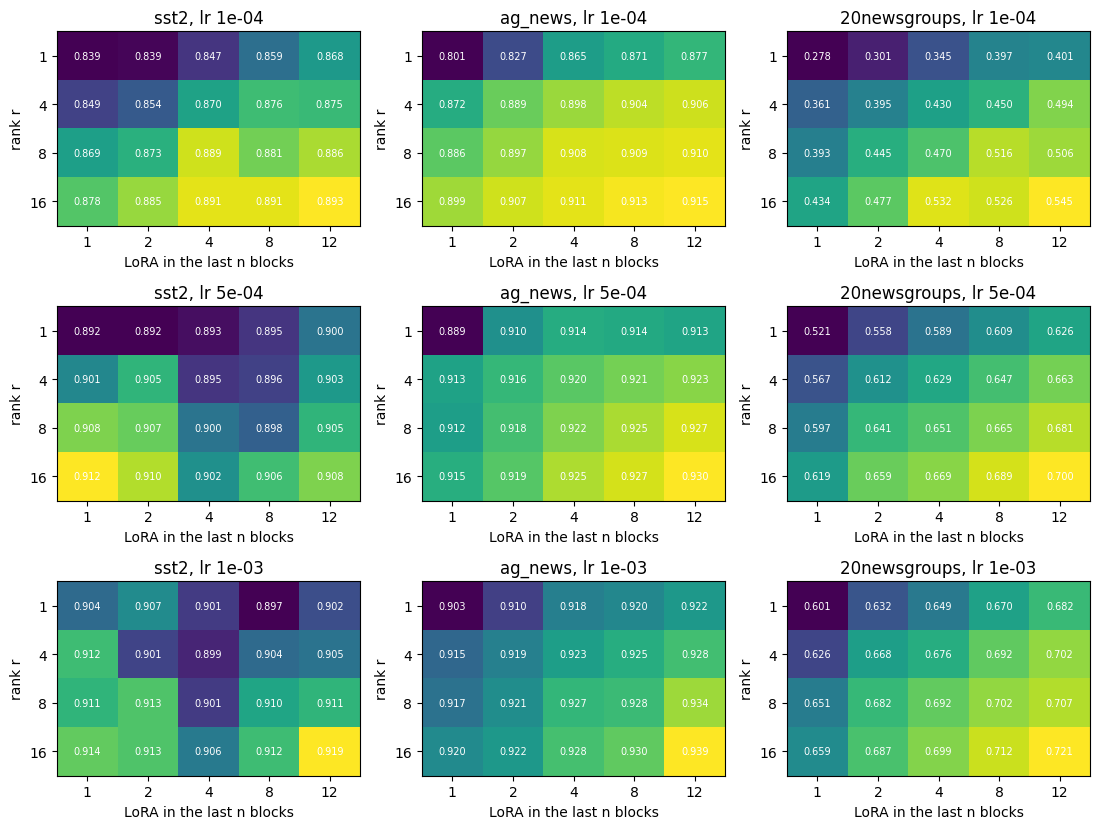

best for 20newsgroups: r=16, last 12 blocks, lr 1e-03 -> 0.721 +- 0.004
best for ag_news     : r=16, last 12 blocks, lr 1e-03 -> 0.939 +- 0.002
best for sst2        : r=16, last 12 blocks, lr 1e-03 -> 0.919 +- 0.004
best overall: {'r': 16, 'last_layers': 12, 'lr': 0.001} -> mean accuracy 0.860
cheapest within half a point: r=16, last 12 blocks, lr 1e-03 -> 0.860


In [16]:
# NEW 12: results per dataset and the default values to report
if not grid:
    print("no grid results yet, set DO_GRIDSEARCH = True in the config cell")
else:
    grid_df = pd.DataFrame(grid)
    fig, axes = plt.subplots(len(GRID_LRS), len(DATA), figsize=(3.7 * len(DATA), 2.8 * len(GRID_LRS)), squeeze=False)
    for (lr, name), ax in zip([(lr, name) for lr in GRID_LRS for name in DATA], axes.flat):   # one row per learning rate
        t = grid_df[(grid_df.dataset == name) & (grid_df.lr == lr)].pivot_table(index="rank", columns="last_layers", values="accuracy")   # mean over seeds
        ax.imshow(t.values, cmap="viridis", aspect="auto")
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                ax.text(j, i, f"{t.values[i, j]:.3f}", ha="center", va="center", fontsize=7, color="white")
        ax.set(title=f"{name}, lr {lr:.0e}", xticks=range(t.shape[1]), xticklabels=t.columns, yticks=range(t.shape[0]), yticklabels=t.index,
               xlabel="LoRA in the last n blocks", ylabel="rank r")
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, "grid.png"), dpi=200)
    plt.show()

    per_dataset = grid_df.groupby(["dataset", "rank", "last_layers", "lr"]).accuracy.agg(["mean", "std"]).reset_index()
    for name, g in per_dataset.groupby("dataset"):
        b = g.loc[g["mean"].idxmax()]
        print(f"best for {name:12}: r={int(b['rank'])}, last {int(b.last_layers)} blocks, lr {b.lr:.0e} -> {b['mean']:.3f} +- {b['std']:.3f}")
    overall = grid_df.groupby(["rank", "last_layers", "lr"]).agg(accuracy=("accuracy", "mean"), trainable=("trainable", "mean")).reset_index()
    overall = overall.sort_values("accuracy", ascending=False)
    best = overall.iloc[0]
    cheap = overall[overall.accuracy >= best.accuracy - 0.005].sort_values("trainable").iloc[0]   # within half a point
    DEFAULTS = {"r": int(best["rank"]), "last_layers": int(best.last_layers), "lr": float(best.lr)}
    print(f"best overall: {DEFAULTS} -> mean accuracy {best.accuracy:.3f}")
    print(f"cheapest within half a point: r={int(cheap['rank'])}, last {int(cheap.last_layers)} blocks, lr {cheap.lr:.0e} -> {cheap.accuracy:.3f}")
    overall.to_csv(os.path.join(OUTPUT_DIR, "grid_overall.csv"), index=False)
    overall.head(8).round(4)
